# Data-driven modeling basics — regression, overfitting, regularization

The whole Part-I pipeline on one 1-D problem: fit $y=\sin(2\pi x)+$noise from a few samples. We see **underfitting vs overfitting**, the role of **train/validation/test**, and how **regularization** helps.

### Setup, target function, and the train/validation split

Import NumPy, PyTorch and Matplotlib, apply the course plotting style, set `float64` as the default dtype, and **fix the seeds** (`torch` and `numpy`) so the noisy data and every fit are reproducible. The target is the curved function
$$ f(x) = \sin(2\pi x), \qquad x\in[0,1], $$
sampled at $n=16$ random points and corrupted with Gaussian noise, $y_i = f(x_i) + \varepsilon_i,\ \varepsilon_i\sim\mathcal N(0,0.15^2)$. The points are split **by location**, not at random: training is everything with $x\le 0.6$, validation everything with $x>0.6$. That turns validation into a small **extrapolation** test — the held-out points sit to the right of all training data. `FIG` is where the dual light/dark figures are written.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join('..','..')))  # -> python/
import numpy as np, torch, matplotlib.pyplot as plt
from pyutils import pinn_core as pc
from pyutils.pinn_core import MLP
from pyutils import save_dual, fg, muted
torch.set_default_dtype(torch.float64); torch.manual_seed(0); np.random.seed(0)
pc.set_plot_style()
FIG = os.path.abspath(os.path.join('..','figures')); os.makedirs(FIG, exist_ok=True)
f = lambda x: np.sin(2*np.pi*x)
n=16; x=np.sort(np.random.rand(n)); y=f(x)+0.15*np.random.randn(n)
# split: train / validation / test
itr,iva = x<=0.6, (x>0.6)
xtr,ytr=x[itr],y[itr]; xva,yva=x[iva],y[iva]
xfine=np.linspace(0,1,200)
print(f'{itr.sum()} train, {iva.sum()} validation points')

9 train, 7 validation points


The print confirms the budget: **9 training points ($x\le0.6$) and 7 validation points ($x>0.6$)** — only 16 samples in all. Because the split is spatial, the validation set lies entirely beyond the training support, so any model that looks great on train but wanders for $x>0.6$ will be exposed. This tiny, noisy, gap-to-the-right dataset is reused by every fit below.

## Polynomial regression: under- vs over-fitting

Fit polynomials $\hat y=\sum_{k=0}^{d} w_k\,x^k$ of increasing degree $d$ by **least squares** on the training points. Stacking the powers of $x$ into a Vandermonde design matrix $\mathbf{A}$, each fit solves
$$ \min_{\boldsymbol w}\ \big\lVert \mathbf{A}\boldsymbol w - \boldsymbol y_{\mathrm{tr}}\big\rVert_2^2 $$
via `np.linalg.lstsq` (the normal-equation solution $\boldsymbol w^\star=(\mathbf A^\top\mathbf A)^{-1}\mathbf A^\top\boldsymbol y$). The cell fits every degree $d=1,\dots,12$, draws the fits for $d\in\{1,3,12\}$, and reports the validation MSE. Low degree **underfits** (too rigid to follow the sine); high degree **overfits** — near-zero training error but wild behaviour on the held-out points at $x>0.6$.

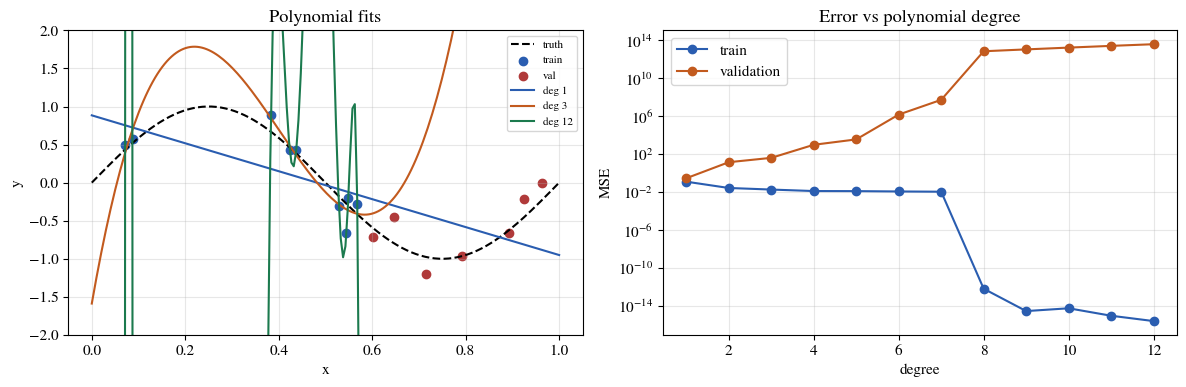

validation MSE: deg1=0.305 deg3=42.932 deg12=40564740909372.289


In [2]:
def polyfit_eval(deg, xq):
    A=np.vander(xtr,deg+1); w,_,_,_=np.linalg.lstsq(A,ytr,rcond=None)
    return np.vander(xq,deg+1)@w
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].plot(xfine,f(xfine),'k--',label='truth'); ax[0].scatter(xtr,ytr,c='C0',label='train'); ax[0].scatter(xva,yva,c='C3',label='val')
for d in [1,3,12]:
    ax[0].plot(xfine,polyfit_eval(d,xfine),label=f'deg {d}')
ax[0].set_ylim(-2,2); ax[0].legend(fontsize=8); ax[0].set(title='Polynomial fits',xlabel='x',ylabel='y')
degs=range(1,13); etr=[];eva=[]
for d in degs:
    etr.append(np.mean((polyfit_eval(d,xtr)-ytr)**2)); eva.append(np.mean((polyfit_eval(d,xva)-yva)**2))
ax[1].semilogy(list(degs),etr,'-o',label='train'); ax[1].semilogy(list(degs),eva,'-o',label='validation')
ax[1].set(title='Error vs polynomial degree',xlabel='degree',ylabel='MSE'); ax[1].legend()
plt.tight_layout(); plt.show()
print('validation MSE: deg1=%.3f deg3=%.3f deg12=%.3f'%(eva[0],eva[2],eva[11]))

The printed validation MSE climbs catastrophically with degree: **deg 1 = 0.305, deg 3 = 42.9, deg 12 ≈ 4×10¹³**. The left panel shows why — the degree-1 line is too stiff to follow $\sin(2\pi x)$, while the degree-12 curve threads the 9 training points but oscillates so violently it shoots far outside the plotted $[-2,2]$ window. The right panel (log scale) is the classic diagnostic: **training MSE falls monotonically toward zero** as degree rises (9 points are easily interpolated by a high-degree polynomial), while **validation MSE turns sharply upward** — the held-out points sit at $x>0.6$, outside the fitted range, where high-degree polynomials diverge. Training error is not the honest signal; the widening gap to the validation curve is.

## Neural network with and without L2 regularization

Swap the fixed polynomial basis for a **learned** one: an MLP `MLP([1, 64, 64, 1])` — two hidden layers of 64 `tanh` units — trained on the 9 training points by 4000 Adam steps (`lr=5e-3`) minimising the MSE data loss $\frac1n\sum_i(\hat y_i-y_i)^2$. With that much capacity and so little data it overfits. The remedy is **L2 regularization** (weight decay): add a penalty on the weights to the cost,
$$ \mathcal L(\boldsymbol\theta) = \mathcal L_{\mathrm{data}}(\boldsymbol\theta) + \lambda\,\lVert\boldsymbol\theta\rVert_2^2, $$
supplied here through Adam's `weight_decay`. The cell fits twice — $\lambda=0$ (no reg) and $\lambda=10^{-2}$ (L2) — and scores each by MSE against the *true* $\sin(2\pi x)$ over all of $[0,1]$.

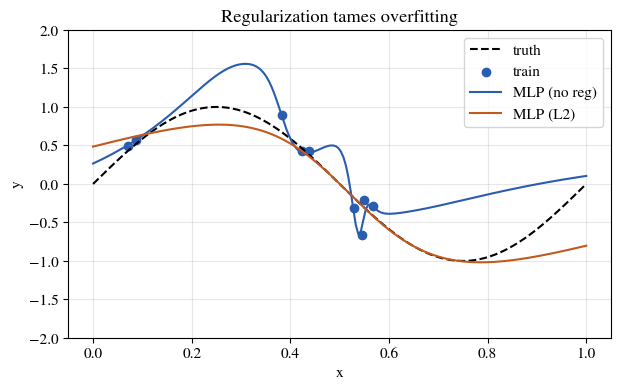

fit-to-truth MSE  no-reg=0.209  L2=0.057


In [3]:
Xtr=torch.tensor(xtr).reshape(-1,1); Ytr=torch.tensor(ytr).reshape(-1,1)
Xfine=torch.tensor(xfine).reshape(-1,1)
def fit_mlp(wd):
    torch.manual_seed(0); net=MLP([1,64,64,1]); opt=torch.optim.Adam(net.parameters(),lr=5e-3,weight_decay=wd)
    for _ in range(4000):
        opt.zero_grad(); loss=((net(Xtr)-Ytr)**2).mean(); loss.backward(); opt.step()
    with torch.no_grad(): return net(Xfine).numpy().ravel()
y_no=fit_mlp(0.0); y_wd=fit_mlp(1e-2)
plt.figure(figsize=(7,4)); plt.plot(xfine,f(xfine),'k--',label='truth')
plt.scatter(xtr,ytr,c='C0',label='train')
plt.plot(xfine,y_no,label='MLP (no reg)'); plt.plot(xfine,y_wd,label='MLP (L2)')
plt.ylim(-2,2); plt.legend(); plt.title('Regularization tames overfitting'); plt.xlabel('x'); plt.ylabel('y'); plt.show()
mse=lambda yq: np.mean((yq-f(xfine))**2)
print(f'fit-to-truth MSE  no-reg={mse(y_no):.3f}  L2={mse(y_wd):.3f}')

The fit-to-truth MSE drops from **0.209 (no reg) to 0.057 (L2)** — about 3.7× closer to the true sine across $[0,1]$. In the figure the unregularized MLP overfits the 9 left-side points and then wanders once it runs out of data past $x\approx0.6$, whereas the L2 curve stays smooth and hugs the dashed truth. The penalty $\lambda\lVert\boldsymbol\theta\rVert^2$ buys generalisation by shrinking the weights — trading a little training fit for a much better held-out fit, the same $\mathcal L_{\mathrm{data}}+\lambda R$ template the slides use with $R=\lVert\boldsymbol\theta\rVert^2$.

## From a line to a deep network — the escalation behind the slides

Three figures used on the DDM slides make the network diagram concrete. A **linear unit** (an MLP with *no* hidden layer) underfits a curved target; **one hidden layer of `tanh` units** bends to fit it; and a **deep `tanh` network** approximates an arbitrarily wiggly function with *no* hand-chosen features — universal approximation. Same cost (MSE), same optimizer (Adam); only the model capacity changes.

An MLP stacks affine maps and nonlinear activations,
$$ \boldsymbol h^{(\ell)} = \sigma\!\big(\mathbf W^{(\ell)}\boldsymbol h^{(\ell-1)} + \boldsymbol b^{(\ell)}\big), \qquad \hat y = \mathbf W^{(L)}\boldsymbol h^{(L-1)} + b^{(L)}\ \text{(linear readout)}, $$
with $\sigma=\tanh$; **linear regression is exactly the case with no hidden layer**. This first cell fits that degenerate case to a fresh target $g_1(x)=\sin(2\pi x)$ (40 points, noise $0.08$) as a closed-form least-squares line, saved as `ddm_ex_line`.

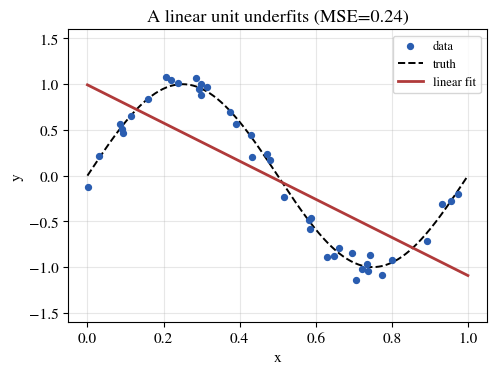

In [4]:
# ---- ddm_ex_line: a linear unit (no hidden layer) underfits a curved target --
rng_ex = np.random.default_rng(3)
g1 = lambda x: np.sin(2*np.pi*x)
xg = np.linspace(0, 1, 300)
xd = np.sort(rng_ex.uniform(0, 1, 40)); yd = g1(xd) + 0.08*rng_ex.standard_normal(40)

# linear regression == an MLP with no hidden layer: closed-form least-squares line
A1 = np.vstack([xd, np.ones_like(xd)]).T
wlin, *_ = np.linalg.lstsq(A1, yd, rcond=None)
ylin = np.vstack([xg, np.ones_like(xg)]).T @ wlin
mse_lin = np.mean((A1 @ wlin - yd)**2)

def plot_ddm_ex_line():
    fig, ax = plt.subplots(figsize=(5.4, 3.8))
    ax.scatter(xd, yd, s=18, color='C0', zorder=3, label='data')
    ax.plot(xg, g1(xg), '--', color=fg(), lw=1.4, label='truth')
    ax.plot(xg, ylin, color='C3', lw=2, label='linear fit')
    ax.set(xlabel='x', ylabel='y', ylim=(-1.6, 1.6),
           title=f'A linear unit underfits (MSE={mse_lin:.2f})')
    ax.legend(loc='upper right', fontsize=9)

save_dual(plot_ddm_ex_line, 'ddm_ex_line', FIG); plt.show()

`ddm_ex_line.png` — the best possible straight line through the noisy sine, and it is hopeless: it slices through the middle of the wave, over-shooting the crest near $x=0.25$ and under-shooting the trough near $x=0.75$, with **MSE = 0.24**. A line has no way to bend, so no amount of optimisation helps — this is the underfitting floor the hidden layer will break.

The same data, one hidden layer added: `fit_mlp_ex([1, 8, 1], ...)` — an MLP with **8 `tanh` hidden units**, the same MSE loss and Adam optimiser (4000 steps). This is the smallest step up from the line: a single learned feature layer $\boldsymbol h=\sigma(\mathbf W^{(1)}x+\boldsymbol b^{(1)})$ feeding the same linear readout, saved as `ddm_ex_nonlinear`.

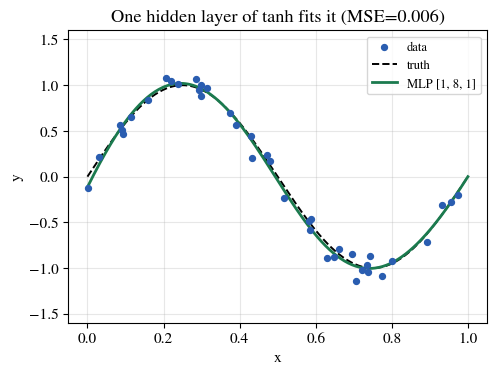

In [5]:
# ---- ddm_ex_nonlinear: one hidden layer of tanh units recovers the curve -----
def fit_mlp_ex(layers, xd, yd, iters=4000, lr=5e-3, seed=0):
    torch.manual_seed(seed)
    net = MLP(layers)
    Xt = torch.tensor(xd).reshape(-1, 1); Yt = torch.tensor(yd).reshape(-1, 1)
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    for _ in range(iters):
        opt.zero_grad(); loss = ((net(Xt) - Yt)**2).mean(); loss.backward(); opt.step()
    with torch.no_grad():
        yq = net(torch.tensor(xg).reshape(-1, 1)).numpy().ravel()
    return net, yq

net_h, yh = fit_mlp_ex([1, 8, 1], xd, yd, iters=4000)
mse_h = np.mean((net_h(torch.tensor(xd).reshape(-1, 1)).detach().numpy().ravel() - yd)**2)

def plot_ddm_ex_nonlinear():
    fig, ax = plt.subplots(figsize=(5.4, 3.8))
    ax.scatter(xd, yd, s=18, color='C0', zorder=3, label='data')
    ax.plot(xg, g1(xg), '--', color=fg(), lw=1.4, label='truth')
    ax.plot(xg, yh, color='C2', lw=2, label='MLP [1, 8, 1]')
    ax.set(xlabel='x', ylabel='y', ylim=(-1.6, 1.6),
           title=f'One hidden layer of tanh fits it (MSE={mse_h:.3f})')
    ax.legend(loc='upper right', fontsize=9)

save_dual(plot_ddm_ex_nonlinear, 'ddm_ex_nonlinear', FIG); plt.show()

`ddm_ex_nonlinear.png` — the eight-unit network now overlays the dashed truth almost perfectly across the whole period, with **MSE = 0.006**, roughly **40× lower** than the line's 0.24. Nothing changed but the model: same loss, same optimiser, same 40 points. The hidden layer supplied the learned features $\boldsymbol\phi_{\boldsymbol\theta}(x)$ a straight line could not.

Now a genuinely wiggly target that no low-order fixed basis can capture:
$$ g_2(x) = \sin(2\pi x) + \tfrac12\sin(6\pi x) + \tfrac14\sin(12\pi x), $$
sampled at 160 points (noise $0.03$). As a foil, fit a **fixed cubic basis** (`np.vander(x,4)`, hand-chosen features) by least squares; then let a **deep network** `MLP([1, 64, 64, 1])` learn its own features (8000 Adam steps, `lr=3e-3`). This produces the `ddm_ex_universal` figure.

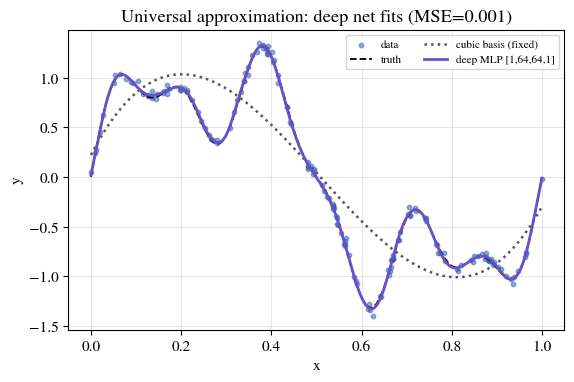

cubic-basis MSE=0.132   deep-MLP MSE=0.001


In [6]:
# ---- ddm_ex_universal: a deep tanh network is a universal approximator --------
# A genuinely wiggly target that no low-order fixed basis captures.
g2 = lambda x: np.sin(2*np.pi*x) + 0.5*np.sin(6*np.pi*x) + 0.25*np.sin(12*np.pi*x)
xd2 = np.sort(rng_ex.uniform(0, 1, 160)); yd2 = g2(xd2) + 0.03*rng_ex.standard_normal(160)

# A cubic polynomial basis (fixed, hand-chosen features) as a foil.
Ac = np.vander(xd2, 4); wc, *_ = np.linalg.lstsq(Ac, yd2, rcond=None)
ycub = np.vander(xg, 4) @ wc

# A deep tanh network learns its own features instead.
net_d, yd_fit = fit_mlp_ex([1, 64, 64, 1], xd2, yd2, iters=8000, lr=3e-3)
mse_d = np.mean((net_d(torch.tensor(xd2).reshape(-1,1)).detach().numpy().ravel() - yd2)**2)

def plot_ddm_ex_universal():
    fig, ax = plt.subplots(figsize=(6.4, 3.9))
    ax.scatter(xd2, yd2, s=10, color='C0', alpha=0.5, zorder=2, label='data')
    ax.plot(xg, g2(xg), '--', color=fg(), lw=1.3, label='truth')
    ax.plot(xg, ycub, ':', color=muted(), lw=1.8, label='cubic basis (fixed)')
    ax.plot(xg, yd_fit, color='C4', lw=2, label='deep MLP [1,64,64,1]')
    ax.set(xlabel='x', ylabel='y',
           title=f'Universal approximation: deep net fits (MSE={mse_d:.3f})')
    ax.legend(loc='upper right', fontsize=8, ncol=2)

save_dual(plot_ddm_ex_universal, 'ddm_ex_universal', FIG); plt.show()
print(f'cubic-basis MSE={np.mean((np.vander(xd2,4)@wc - yd2)**2):.3f}   deep-MLP MSE={mse_d:.3f}')

`ddm_ex_universal.png` — the cubic basis (dotted) can only draw one gentle hump and misses every fast oscillation (**MSE = 0.132**), while the deep `tanh` net tracks all three frequencies of $g_2$ almost exactly (**MSE = 0.001**, ~130× better). No features were hand-picked: the two hidden layers *learned* a basis rich enough to represent the superposition of sines. That is the **universal approximation** theorem made visible — and the same flexibility that, unchecked, let the degree-12 polynomial explode, which is why regularization and honest validation matter.

**Takeaways.** Model complexity must match the data; validation error (not training error) is the honest signal; regularization buys generalization. The same network, loss and optimizer reappear in every later module.